In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(
/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(
/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(


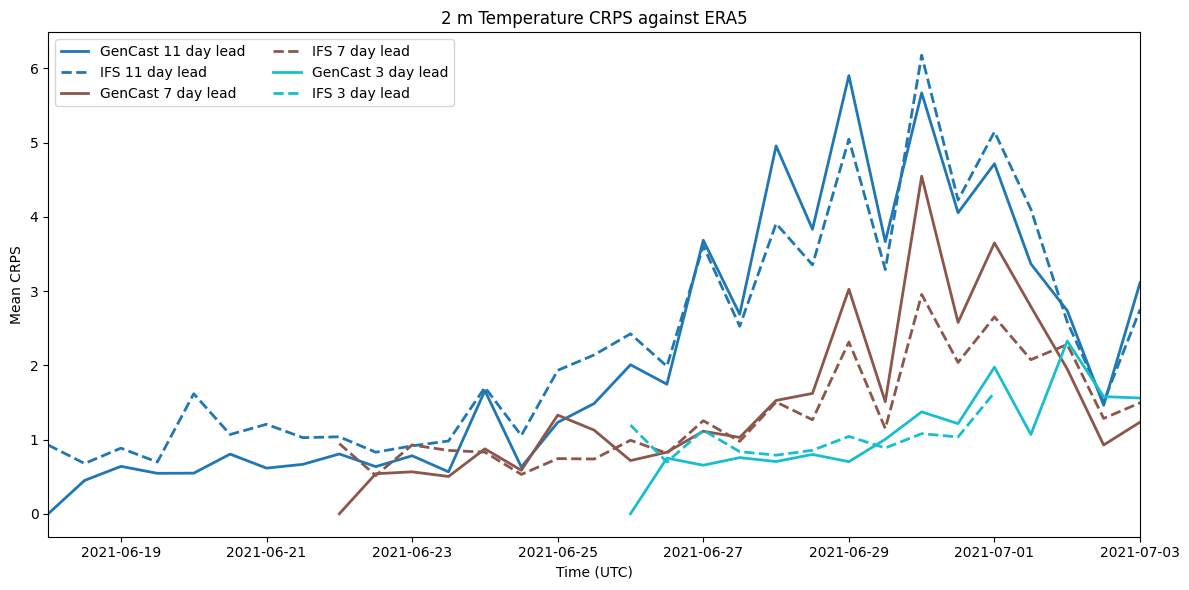

In [9]:
REGION = (45, 52, -123, -119)
ERA5_NC = "era5_pnw025_2021.nc"

runs = [
    {
        "label": "11 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-18.nc",
        "start_time": "2021-06-18 00:00:00",
    },
    {
        "label": "7 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-22.nc",
        "start_time": "2021-06-22 00:00:00",
    },
    {
        "label": "3 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
        "start_time": "2021-06-26 00:00:00",
    },
]

GENCAST_VAR = "2m_temperature"
IFS_VAR = "t2m"
ERA5_VAR = "t2m"

def standardize_latlon_names(ds):
    """
    Rename common latitude/longitude coordinate names to lat/lon.
    Adjust this if your files use other names.
    """
    rename = {}
    candidates = [
        ("latitude", "lat"),
        ("longitude", "lon"),
        ("Latitude", "lat"),
        ("Longitude", "lon"),
        ("LATITUDE", "lat"),
        ("LONGITUDE", "lon"),
    ]
    for old, new in candidates:
        if old in ds.coords or old in ds.dims:
            rename[old] = new
    if rename:
        ds = ds.rename(rename)
    return ds


def normalize_longitude(ds, lon_name="lon"):
    """
    Convert 0..360 longitudes to -180..180 so all datasets line up.
    If your data are already in -180..180, this is a no-op.
    """
    if lon_name not in ds.coords:
        return ds

    lon = ds[lon_name]
    if float(lon.max()) > 180:
        ds = ds.assign_coords({lon_name: ((lon + 180) % 360) - 180}).sortby(lon_name)
    return ds


def pick_ensemble_dim(da):
    """
    Find the ensemble/member dimension if it exists.
    If no ensemble dimension exists, we will treat the forecast as
    a single-member ensemble.
    """
    for cand in ["member", "ensemble", "number", "realization", "ens"]:
        if cand in da.dims:
            return cand
    return None


def crps_calculation(ensemble, truth):
    ens_members = np.sort(ensemble[np.isfinite(ensemble)])

    if len(ens_members) == 0:
        return np.nan

    if len(ens_members) == 1:
        return abs(ens_members[0] - truth)

    crps = 0.0

    # Pseudo code:
    # CRPS = ∫ (F(y)-H(y-x))² dy
    for k in range(len(ens_members) - 1):

        y_k = ens_members[k]
        y_k1 = ens_members[k + 1]
        dy = y_k1 - y_k

        F_k = (k + 1) / len(ens_members)

        if y_k1 <= truth:
            # interval entirely below observation
            crps += (F_k ** 2) * dy

        elif y_k >= truth:
            # interval entirely above observation
            crps += ((F_k - 1) ** 2) * dy

        else:
            # observation lies inside interval
            crps += (F_k ** 2) * (truth - y_k)
            crps += ((F_k - 1) ** 2) * (y_k1 - truth)

    return crps

def compute_crps(forecast_da, obs_da):
    # Find the ensemble dimension
    ens_dim = None
    for dim in ["sample", "member", "ensemble", "number", "realization"]:
        if dim in forecast_da.dims:
            ens_dim = dim
            break

    if ens_dim is None:
        # Deterministic forecast -> treat as 1-member ensemble
        forecast_da = forecast_da.expand_dims(member=[0])
        ens_dim = "member"

    # CRPS needs the full ensemble vector at each point,
    # so make the ensemble dimension a single chunk.
    if forecast_da.chunks is not None:
        forecast_da = forecast_da.chunk({ens_dim: -1})

    crps = xr.apply_ufunc(
        crps_calculation,
        forecast_da,
        obs_da,
        input_core_dims=[[ens_dim], []],
        output_core_dims=[[]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float],
    )

    return crps

def score_one_initialization(gencast_zarr, ifs_nc, era5_nc, start_time, region=None):
    gc = xr.open_zarr(gencast_zarr)
    ifs = xr.open_dataset(ifs_nc)
    era5 = xr.open_dataset(era5_nc)

    gc = standardize_latlon_names(gc)
    ifs = standardize_latlon_names(ifs)
    era5 = standardize_latlon_names(era5)

    gc = normalize_longitude(gc)
    ifs = normalize_longitude(ifs)
    era5 = normalize_longitude(era5)

    gc_t = gc[GENCAST_VAR]
    ifs_t = ifs[IFS_VAR]
    era5_t = era5[ERA5_VAR]

    # GenCast time is elapsed time, with 0 = forecast init
    gc_t = gc_t.sel(time=slice(np.timedelta64(0, "ns"), None))

    gc_valid_times = pd.Timestamp(start_time) + pd.to_timedelta(gc_t["time"].values)
    gc_t = gc_t.assign_coords(time=gc_valid_times).sortby("time")

    # Align IFS and ERA5 to the same valid times
    ifs_t = ifs_t.reindex(time=gc_valid_times, method="nearest", tolerance="1H").sortby("time")
    era5_t = era5_t.reindex(time=gc_valid_times, method="nearest", tolerance="1H").sortby("time")

    # Use GenCast grid as the reference grid
    if "lat" not in gc.coords or "lon" not in gc.coords:
        raise ValueError("Could not find lat/lon coordinates in the GenCast dataset after renaming.")

    target_lat = gc["lat"]
    target_lon = gc["lon"]

    ifs_on_gc = ifs_t.interp(lat=target_lat, lon=target_lon)
    era5_on_gc = era5_t.interp(lat=target_lat, lon=target_lon)

    # Optional region subset
    if region is not None:
        lat_min, lat_max, lon_min, lon_max = region
        gc_t = gc_t.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
        ifs_on_gc = ifs_on_gc.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
        era5_on_gc = era5_on_gc.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

    crps_gencast = compute_crps(gc_t, era5_on_gc)
    crps_ifs = compute_crps(ifs_on_gc, era5_on_gc)

    crps_gencast_mean = crps_gencast.mean(dim=[d for d in crps_gencast.dims if d != "time"], skipna=True).squeeze()
    crps_ifs_mean = crps_ifs.mean(dim=[d for d in crps_ifs.dims if d != "time"], skipna=True).squeeze()

    return crps_gencast_mean, crps_ifs_mean


# ============================================================
# Run all initialisations and plot
# ============================================================

results = []

for run in runs:
    crps_gc_mean, crps_ifs_mean = score_one_initialization(
        run["gencast"],
        run["ifs"],
        ERA5_NC,
        run["start_time"],
        region=REGION,
    )

    results.append(
        {
            "label": run["label"],
            "gc": crps_gc_mean,
            "ifs": crps_ifs_mean,
        }
    )

plt.figure(figsize=(12, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(results)))

for color, res in zip(colors, results):
    plt.plot(
        res["gc"]["time"].values,
        res["gc"].values.ravel(),
        color=color,
        linestyle="-",
        linewidth=2,
        label=f"GenCast {res['label']}",
    )
    plt.plot(
        res["ifs"]["time"].values,
        res["ifs"].values.ravel(),
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"IFS {res['label']}",
    )

plt.xlabel("Time (UTC)")
plt.ylabel("Mean CRPS")
plt.xlim(pd.Timestamp("2021-06-18"), pd.Timestamp("2021-07-03"))
plt.title("2 m Temperature CRPS against ERA5")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

# 7) Optional: save the per-location CRPS fields
#crps_gencast.to_netcdf("crps_gencast.nc")
#crps_ifs.to_netcdf("crps_ifs.nc")

In [6]:
print(gc_t["time"].dtype)
print(gc_t["time"].values[:5])

datetime64[ns]
['2021-06-17T12:00:00.000000000' '2021-06-18T00:00:00.000000000'
 '2021-06-18T12:00:00.000000000' '2021-06-19T00:00:00.000000000'
 '2021-06-19T12:00:00.000000000']
